```30/10/2026```

Explore toroidal mirror foci properties.

In [13]:
import numpy as np
import matplotlib.pyplot as plt

In [14]:
from shadowpy.si_beamlines import CAXSim

In [15]:
cax = CAXSim()

 Generated         5000  rays out of       100000
                  10000
                  15000
                  20000
                  25000
                  30000
                  35000
                  40000
                  45000
                  50000
                  55000
                  60000
                  65000
                  70000
                  75000
                  80000
                  85000
                  90000
                  95000
                 100000
 Exit from SOURCE
 Call to RESET
 Exit from RESET
Traced through element 1: MASK_A1
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR

In [16]:
print(cax.mirror.shadow_oe.mirinfo())

+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
********************   OPTICAL ELEMENT  DESCRIPTION   ********************


+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Surface figure was defined as: TOROIDAL     
Element type                            REFLECTOR
Reflectivity                            OFF
Mirror dimensions ( rectangular ):
          X plus: 4.000000, X minus: -4.000000, Y plus: 110.000000, Y minus: -110.000000
+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Central Axis parameters :
Source Plane Distance                    2000.000000 mm
Image  Plane                             0.000000 mm
Incidence Angle                          88.924000 deg
Reflection/Diffraction Angle             88.924000 deg
Mirror parameters                       EXTERNAL
Parameters used follow:
   Major Radius (optical)     901300.000000 mm
   Minor Radius               318.400000 mm
Source of t

In [17]:
print(cax.dvf_B1.shadow_oe.mirinfo())

+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
********************   OPTICAL ELEMENT  DESCRIPTION   ********************


+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Element type                            EMPTY
+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Central Axis parameters :
Source Plane Distance                    12641.000000 mm
Image  Plane                             0.000000 mm
Incidence Angle                          0.000000 deg
Reflection/Diffraction Angle             180.000000 deg
  SCREENS:     1 defined 
    SCREEN 1 : 
      AFTER o.e.       at 0.000000 mm
+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
***************                 E N D                  ***************
+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++



In [18]:
np.deg2rad(90-88.924000)

0.01877974275145887

In [19]:
theta0 = 18.7797e-3 # rad
p      = 17         # m
Rm     = 901.3      # m
Rs     = 0.3184     # m
z0_dvf = 17.        # m

def focus_x(theta):
    return Rm*np.sin(theta)/2

def focus_y(theta):
    return Rs/(np.sin(theta)*2)

def image_x(theta):
    return (1/focus_x(theta) - 1/p)**(-1)

def image_y(theta):
    return (1/focus_y(theta) - 1/p)**(-1)

In [24]:
RY = np.linspace(0, 0.05, 1000)*1.e-3 # ±0.1 mrad
thetas = RY + theta0

Text(0, 0.5, 'focus [m]')

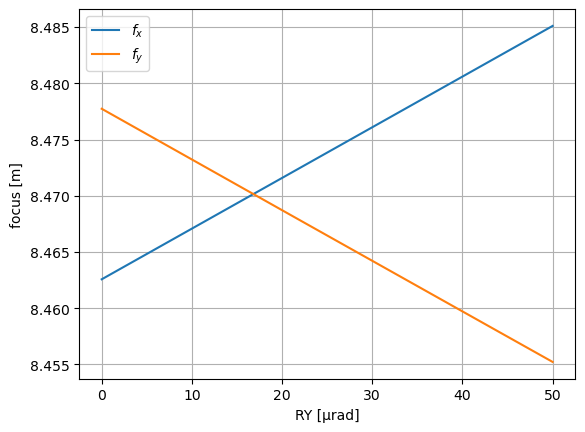

In [25]:

plt.plot(RY*1.e6, focus_x(thetas), label='$f_x$')
plt.plot(RY*1.e6, focus_y(thetas), label='$f_y$')
plt.grid()
plt.legend()
plt.xlabel("RY [μrad]")
plt.ylabel("focus [m]")

Text(0, 0.5, '$z_0$ [mm]')

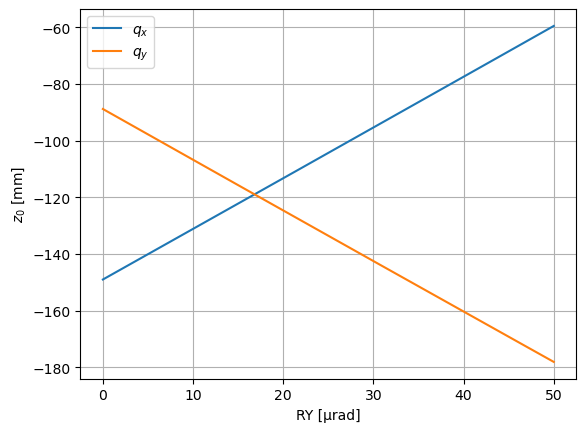

In [26]:

plt.plot(RY*1.e6, (image_x(thetas)-z0_dvf)*1000, label='$q_x$')
plt.plot(RY*1.e6, (image_y(thetas)-z0_dvf)*1000, label='$q_y$')
plt.grid()
plt.legend()
plt.xlabel("RY [μrad]")
plt.ylabel("$z_0$ [mm]")

Text(0, 0.5, 'z [mm]')

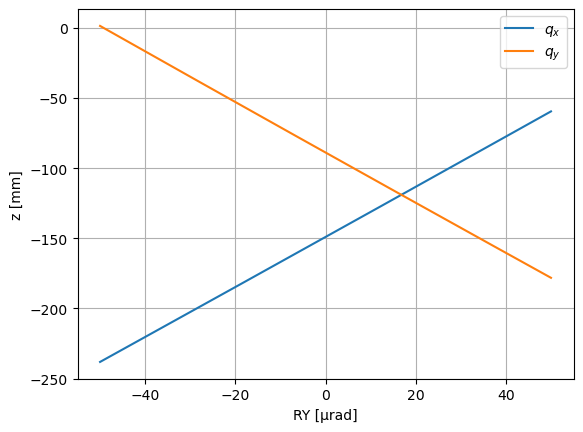

In [74]:
rys = np.linspace(-50, 50, 1000)*1.e-6 # 15-10 μrad


plt.plot(rys*1.e6, (image_x(theta0+rys)-z0_dvf)*1000, label='$q_x$')
plt.plot(rys*1.e6, (image_y(theta0+rys)-z0_dvf)*1000, label='$q_y$')
plt.grid()
plt.legend()
plt.xlabel("RY [μrad]")
plt.ylabel("z [mm]")

In [28]:
i = np.argmin(abs(image_y(thetas) - image_x(thetas)))

In [29]:
print(f"RY for which foci are matched: {RY[i]*1e6:.2f} μrad")
print(f"Position of the image: z={(image_x(thetas[i])-z0_dvf)*1000:.2f} mm")

RY for which foci are matched: 16.82 μrad
Position of the image: z=-118.98 mm


In [64]:
import os
import sys
from shadowpy.si_beamlines import CAXSim
from shadowpy.utils import save_image, Image
sys.path.append(os.path.expanduser("~/repos/cax-scripts/caxscritpts/"))

from image_statistics import Histogram2DAnalyzer

ModuleNotFoundError: No module named 'image_statistics'